In [1]:
#Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#Load the dataset

df = pd.read_csv("Synthetic_Financial_datasets_log.csv")

In [3]:
#Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.head()
df.info()
df.describe()

Number of Rows: 6362620
Number of Columns: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [4]:
#Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [5]:
#Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [6]:
#Check target variable distribution

print(df['isFraud'].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [7]:
#Calculate fraud percentages

fraud_percentage = df['isFraud'].value_counts(normalize=True) * 100

print("Class Distribution (%):")
print(fraud_percentage)

Class Distribution (%):
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


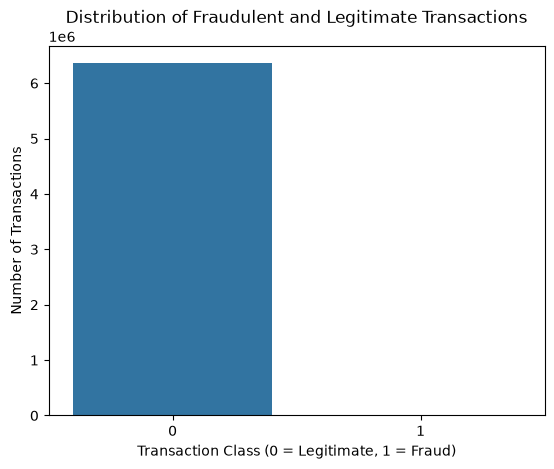

In [8]:
#plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='isFraud')

plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()

In [9]:
#Analyze transaction types

print("Transaction Type Distribution:")
print(df['type'].value_counts())

Transaction Type Distribution:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [10]:
#Analyze unique categorical values

print("Unique Transaction Types:", df['type'].nunique())

print("Unique Origin Accounts:", df['nameOrig'].nunique())

print("Unique Destination Accounts:", df['nameDest'].nunique())

Unique Transaction Types: 5
Unique Origin Accounts: 6353307
Unique Destination Accounts: 2722362


Observations
1. No missing values means we don't need missing-value imputation.
2. No duplicate records means no duplicate removal is necessary.
3. Fraudulent transactions represent only 0.129% of the dataset. This is a serious class imbalance problem.
4. We have five transaction types: CASH_OUT, PAYMENT, CASH_IN, TRANSFER and DEBIT.
The fraud bar is almost invisible because the number of fraudulent transactions is very small compared with legitimate transactions

Exploratory Data Analysis (EDA)

In [11]:
#Fraud distribution by transaction type

fraud_by_type = df.groupby('type')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
)

fraud_by_type['legitimate_transactions'] = (
    fraud_by_type['total_transactions'] -
    fraud_by_type['fraud_transactions']
)

fraud_by_type['fraud_percentage'] = (
    fraud_by_type['fraud_transactions'] /
    fraud_by_type['total_transactions']
) * 100

fraud_by_type.sort_values(
    by='fraud_percentage',
    ascending=False
)

,total_transactions,fraud_transactions,legitimate_transactions,fraud_percentage
type,,,,
TRANSFER,532909,4097,528812,0.768799
CASH_OUT,2237500,4116,2233384,0.183955
CASH_IN,1399284,0,1399284,0.000000
DEBIT,41432,0,41432,0.000000
PAYMENT,2151495,0,2151495,0.000000


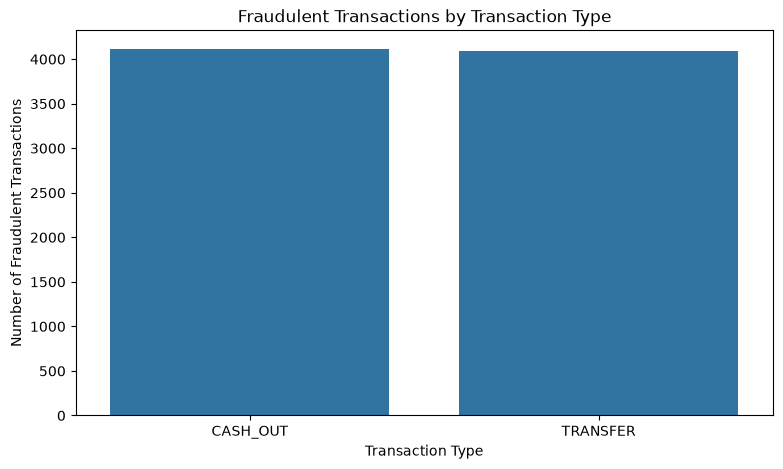

In [12]:
#Visualize fraudulent transactions by type

plt.figure(figsize=(9, 5))

fraud_data = df[df['isFraud'] == 1]

sns.countplot(
    data=fraud_data,
    x='type',
    order=fraud_data['type'].value_counts().index
)

plt.title('Fraudulent Transactions by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Fraudulent Transactions')

plt.show()

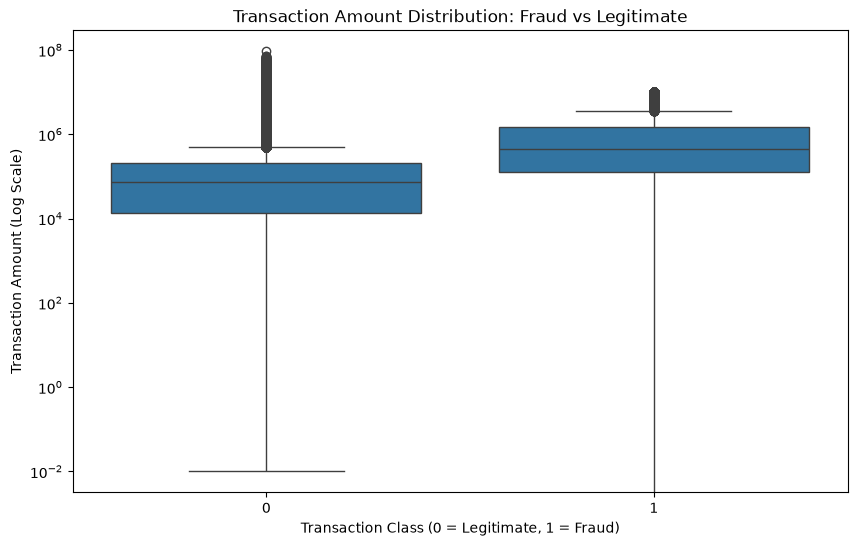

In [13]:
#Compare transaction amounts

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='isFraud',
    y='amount'
)

plt.yscale('log')

plt.title('Transaction Amount Distribution: Fraud vs Legitimate')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transaction Amount (Log Scale)')

plt.show()

In [14]:
#Compare average transaction amounts

amount_comparison = df.groupby('isFraud')['amount'].agg(
    ['mean', 'median', 'min', 'max']
)

amount_comparison.index = ['Legitimate', 'Fraud']

amount_comparison

,mean,median,min,max
Legitimate,1.781970e+05,74684.72,0.01,92445516.64
Fraud,1.467967e+06,441423.44,0.00,10000000.00


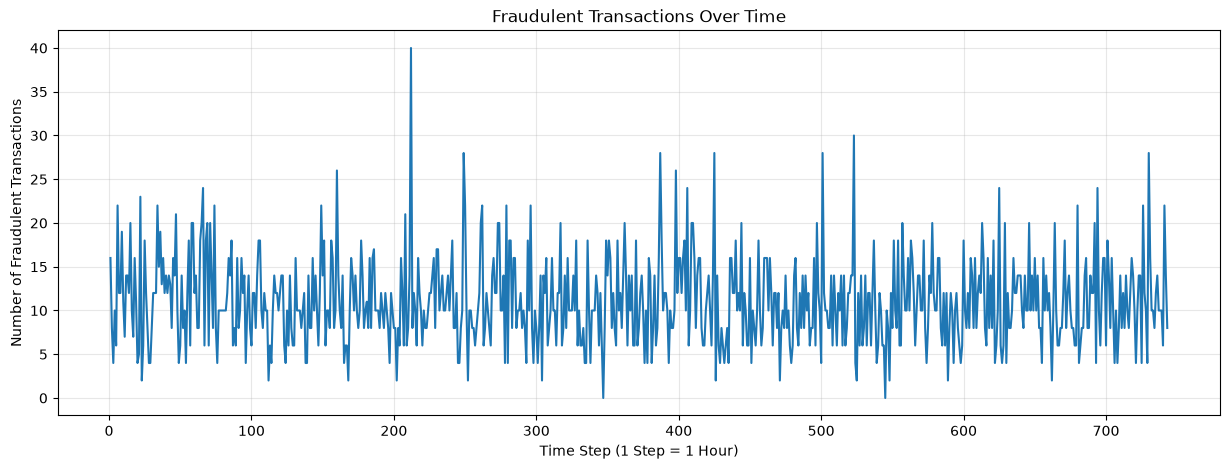

In [15]:
#Time-Based Fraud Analysis


#Fraud transactions by step
fraud_by_step = df.groupby('step')['isFraud'].sum()

plt.figure(figsize=(15, 5))

plt.plot(fraud_by_step.index, fraud_by_step.values)

plt.title('Fraudulent Transactions Over Time')
plt.xlabel('Time Step (1 Step = 1 Hour)')
plt.ylabel('Number of Fraudulent Transactions')

plt.grid(alpha=0.3)
plt.show()

Graph shows:
- Fraud occurs throughout the simulation period.
- Most time steps have approximately 5–15 fraudulent transactions.
- Some time steps experience spikes, reaching around 40 transactions.
- There is no obvious consistent upward or downward trend.
Finding: Fraud occurs throughout the simulation rather than being restricted to a particular period.

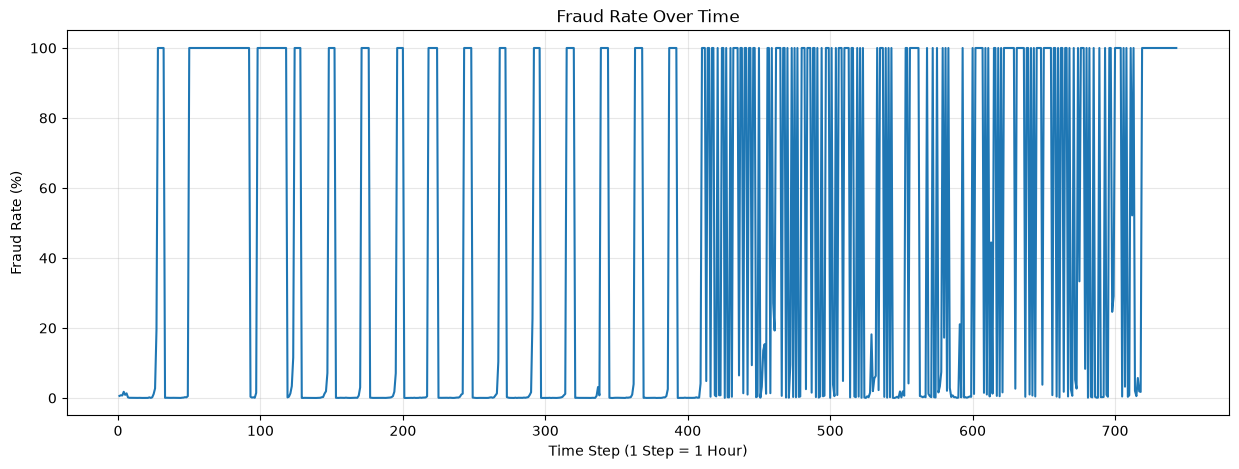

In [16]:
#Fraud rate by step
fraud_rate_by_step = df.groupby('step')['isFraud'].mean() * 100

plt.figure(figsize=(15, 5))

plt.plot(
    fraud_rate_by_step.index,
    fraud_rate_by_step.values
)

plt.title('Fraud Rate Over Time')
plt.xlabel('Time Step (1 Step = 1 Hour)')
plt.ylabel('Fraud Rate (%)')

plt.grid(alpha=0.3)
plt.show()

Second graph has many spikes reaching 100%. This does not necessarily mean fraud suddenly increases.

For example:
- If a particular hour has 1 transaction and that transaction is fraudulent, the fraud rate is 100%.
- If another hour has 10,000 transactions and 10 are fraudulent, the fraud rate is only 0.1%.
Therefore, calculating fraud percentages for individual hours can be misleading when transaction volumes are low.
We need to aggregate the data into daily periods.

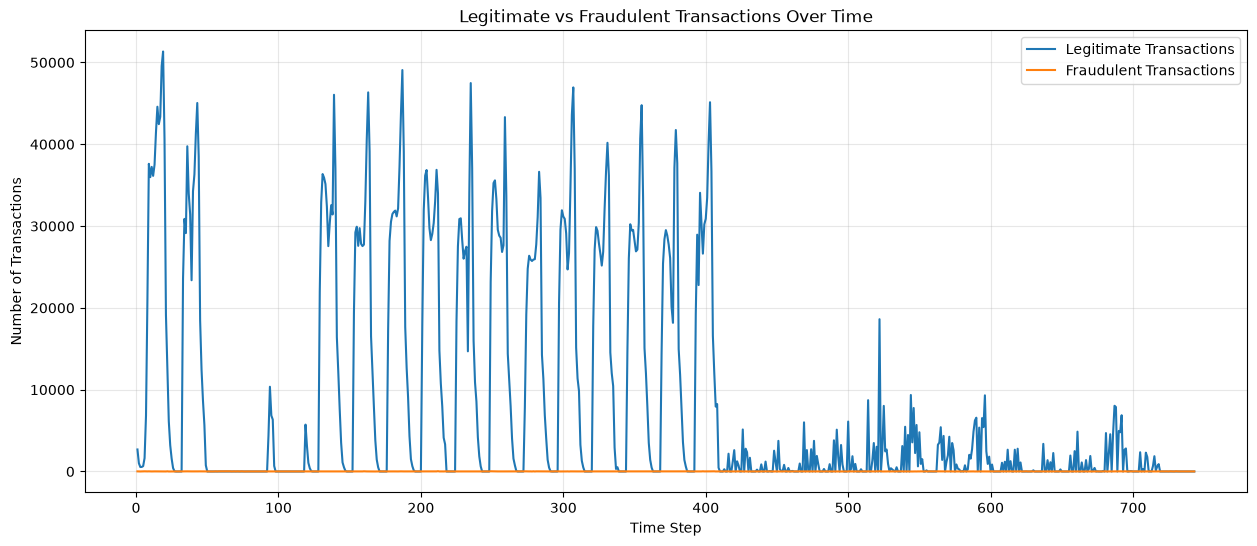

In [17]:
#Overall transaction activity over time

transactions_by_step = df.groupby(
    ['step', 'isFraud']
).size().unstack(fill_value=0)

plt.figure(figsize=(15, 6))

plt.plot(
    transactions_by_step.index,
    transactions_by_step[0],
    label='Legitimate Transactions'
)

plt.plot(
    transactions_by_step.index,
    transactions_by_step[1],
    label='Fraudulent Transactions'
)

plt.title('Legitimate vs Fraudulent Transactions Over Time')
plt.xlabel('Time Step')
plt.ylabel('Number of Transactions')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Third graph shows that legitimate transactions dominate the dataset.

The fraudulent transaction line is almost invisible because both classes share the same Y-axis.

This confirms the severe class imbalance we discovered earlier.

In [18]:
#Daily Fraud Analysis

#Create daily groups

daily_data = df.copy()

daily_data['day'] = ((daily_data['step'] - 1) // 24) + 1

daily_fraud = daily_data.groupby('day').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum')
)

daily_fraud['legitimate_transactions'] = (
    daily_fraud['total_transactions'] -
    daily_fraud['fraud_transactions']
)

daily_fraud['fraud_rate'] = (
    daily_fraud['fraud_transactions'] /
    daily_fraud['total_transactions']
) * 100

daily_fraud

,total_transactions,fraud_transactions,legitimate_transactions,fraud_rate
day,,,,
1,574255,271,573984,0.047192
2,455238,309,454929,0.067877
3,1070,310,760,28.971963
4,28240,262,27978,0.927762
5,9789,252,9537,2.574318
6,441005,228,440777,0.051700
7,420583,272,420311,0.064672
8,449637,278,449359,0.061828
9,417919,255,417664,0.061017


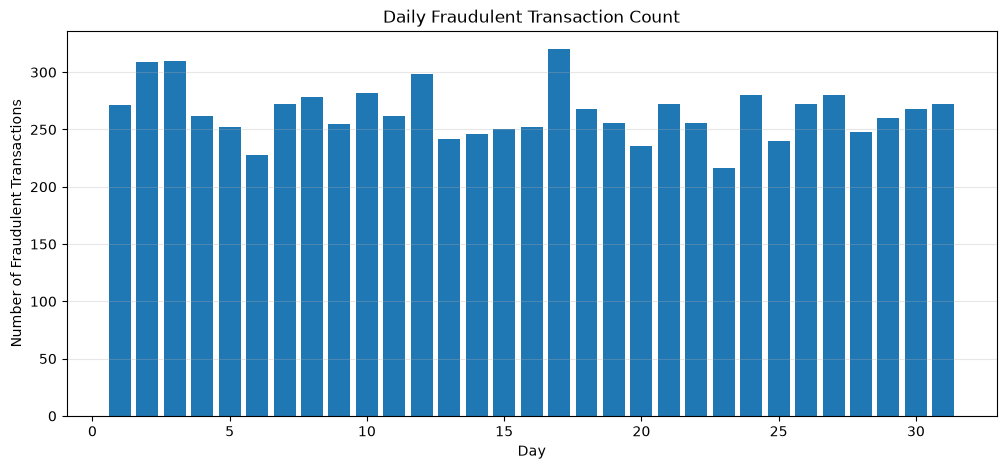

In [19]:
#Daily fraud count

plt.figure(figsize=(12, 5))

plt.bar(
    daily_fraud.index,
    daily_fraud['fraud_transactions']
)

plt.title('Daily Fraudulent Transaction Count')
plt.xlabel('Day')
plt.ylabel('Number of Fraudulent Transactions')

plt.grid(axis='y', alpha=0.3)
plt.show()

Graph shows that fraud counts are relatively consistent across the simulation.
- Most days have approximately 240–310 fraudulent transactions.
- Day 17 has the highest count (320).
- There is no clear increasing or decreasing fraud trend.

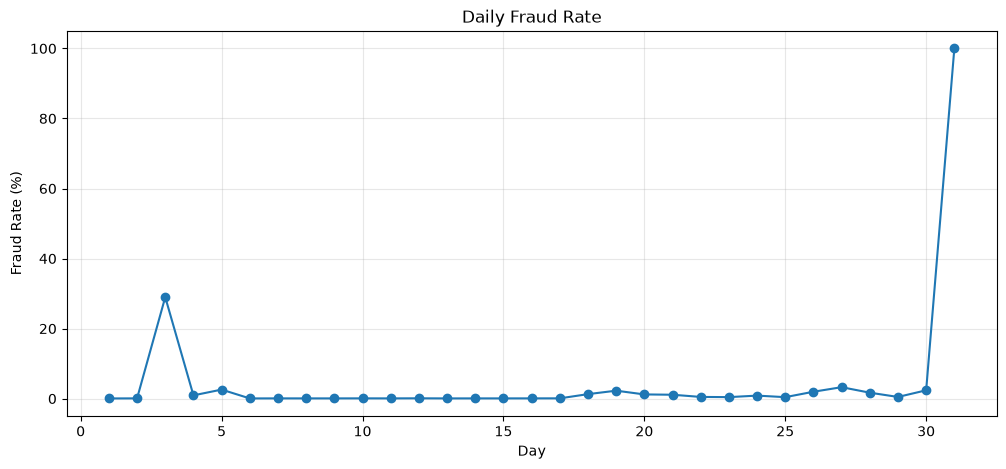

In [20]:
#Daily fraud percentage

plt.figure(figsize=(12, 5))

plt.plot(
    daily_fraud.index,
    daily_fraud['fraud_rate'],
    marker='o'
)

plt.title('Daily Fraud Rate')
plt.xlabel('Day')
plt.ylabel('Fraud Rate (%)')

plt.grid(alpha=0.3)
plt.show()

The 100% fraud rate on Day 31 is particularly suspicious.

It does not necessarily indicate a genuine fraud outbreak. There are only 272 transactions in that group.

Also, Day 31 is an incomplete 24-hour group because the dataset ends at step 743.

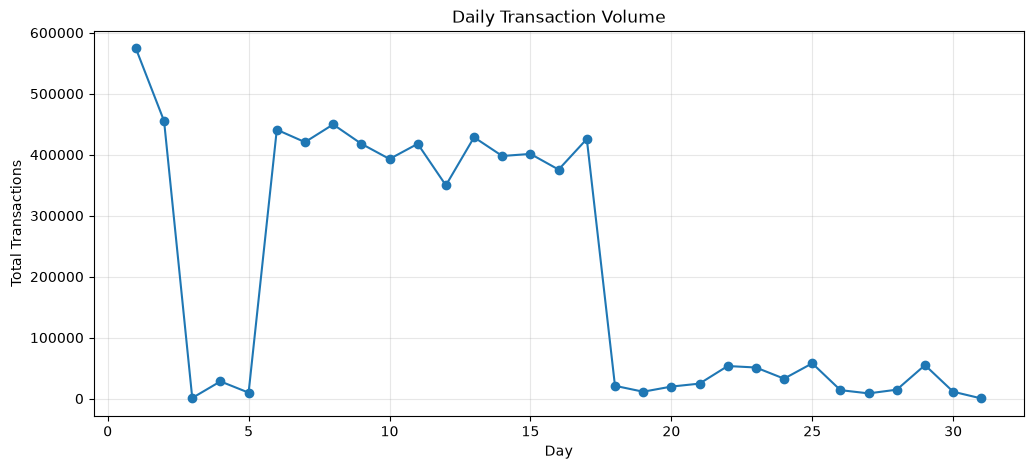

In [21]:
#Daily transaction volume

plt.figure(figsize=(12, 5))

plt.plot(
    daily_fraud.index,
    daily_fraud['total_transactions'],
    marker='o'
)

plt.title('Daily Transaction Volume')
plt.xlabel('Day')
plt.ylabel('Total Transactions')

plt.grid(alpha=0.3)
plt.show()

graph shows substantial variations in transaction volume.

Some groups contain more than 400,000 transactions, while others contain fewer than 15,000.

 conclusion: should not interpret these daily fraud percentages as reliable evidence of changing fraud risk without investigating the underlying hourly transaction counts.

In [22]:
#Investigate unusual time patterns

#Check transaction counts by step

step_analysis = df.groupby('step').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum')
)

step_analysis['fraud_rate'] = (
    step_analysis['fraud_transactions'] /
    step_analysis['total_transactions']
) * 100

print("Total Unique Steps:", df['step'].nunique())

print("\nLowest Transaction Volume Steps:")
print(step_analysis.sort_values(
    'total_transactions'
).head(10))

print("\nHighest Fraud Rate Steps:")
print(step_analysis.sort_values(
    'fraud_rate',
    ascending=False
).head(10))

Total Unique Steps: 743

Lowest Transaction Volume Steps:
      total_transactions  fraud_transactions  fraud_rate
step                                                    
662                    2                   2       100.0
112                    2                   2       100.0
29                     4                   4       100.0
627                    4                   4       100.0
655                    4                   4       100.0
76                     4                   4       100.0
293                    4                   4       100.0
28                     4                   4       100.0
246                    4                   4       100.0
435                    4                   4       100.0

Highest Fraud Rate Steps:
      total_transactions  fraud_transactions  fraud_rate
step                                                    
727                   12                  12       100.0
743                    8                   8       100.0
742

In [23]:
#Investigate the last time window

last_day = df[df['step'] >= 721]

print("Last Time Window Analysis")

print("Total Transactions:", len(last_day))

print("\nFraud Distribution:")
print(last_day['isFraud'].value_counts())

print("\nTransactions by Step:")
print(last_day.groupby('step')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
))

Last Time Window Analysis
Total Transactions: 272

Fraud Distribution:
isFraud
1    272
Name: count, dtype: int64

Transactions by Step:
      total_transactions  fraud_transactions
step                                        
721                    4                   4
722                   10                  10
723                   14                  14
724                   14                  14
725                    4                   4
726                   22                  22
727                   12                  12
728                   10                  10
729                    4                   4
730                   28                  28
731                   16                  16
732                   10                  10
733                   10                  10
734                    8                   8
735                   12                  12
736                   14                  14
737                   10                  10
738     

In [24]:
#Check the suspicious third day

day_3 = df[(df['step'] >= 49) & (df['step'] <= 72)]

print("Day 3 Transaction Analysis")

print("Total Transactions:", len(day_3))

print("\nFraud Distribution:")
print(day_3['isFraud'].value_counts())

print("\nTransaction Count by Step:")
print(day_3.groupby('step')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
))

Day 3 Transaction Analysis
Total Transactions: 1070

Fraud Distribution:
isFraud
0    760
1    310
Name: count, dtype: int64

Transaction Count by Step:
      total_transactions  fraud_transactions
step                                        
49                   764                   4
50                     6                   6
51                    14                  14
52                     8                   8
53                    10                  10
54                     4                   4
55                    12                  12
56                    18                  18
57                     6                   6
58                    20                  20
59                    20                  20
60                    12                  12
61                    14                  14
62                     8                   8
63                     8                   8
64                    18                  18
65                    20             

In [25]:
#Create a separate modelling dataset

# Create a separate dataset for feature engineering

model_df = df[['type', 'amount', 'nameOrig',
               'nameDest', 'isFraud']].copy()

print("Modelling dataset created successfully!")
print("Shape:", model_df.shape)

Modelling dataset created successfully!
Shape: (6362620, 5)


In [26]:
#Extract origin account type

model_df['origin_account_type'] = (
    model_df['nameOrig'].str[0]
)

model_df['origin_account_type'].value_counts()

origin_account_type
C    6362620
Name: count, dtype: int64

In [27]:
#Extract destination account type

model_df['destination_account_type'] = (
    model_df['nameDest'].str[0]
)

model_df['destination_account_type'].value_counts()

destination_account_type
C    4211125
M    2151495
Name: count, dtype: int64

In [28]:
#Apply log transformation to transaction amount

model_df['log_amount'] = np.log1p(model_df['amount'])

print("Original Amount:")
print(model_df['amount'].describe())

print("\nLog Transformed Amount:")
print(model_df['log_amount'].describe())

Original Amount:
count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64

Log Transformed Amount:
count    6.362620e+06
mean     1.084087e+01
std      1.814509e+00
min      0.000000e+00
25%      9.502306e+00
50%      1.122355e+01
75%      1.224876e+01
max      1.834213e+01
Name: log_amount, dtype: float64


In [29]:
#Display our engineered dataset

model_df.head(10)

,type,amount,nameOrig,nameDest,isFraud,origin_account_type,destination_account_type,log_amount
0,PAYMENT,9839.64,C1231006815,M1979787155,0,C,M,9.194276
1,PAYMENT,1864.28,C1666544295,M2044282225,0,C,M,7.531166
2,TRANSFER,181.00,C1305486145,C553264065,1,C,C,5.204007
3,CASH_OUT,181.00,C840083671,C38997010,1,C,C,5.204007
4,PAYMENT,11668.14,C2048537720,M1230701703,0,C,M,9.364703
5,PAYMENT,7817.71,C90045638,M573487274,0,C,M,8.964275
6,PAYMENT,7107.77,C154988899,M408069119,0,C,M,8.869085
7,PAYMENT,7861.64,C1912850431,M633326333,0,C,M,8.969878
8,PAYMENT,4024.36,C1265012928,M1176932104,0,C,M,8.300370
9,DEBIT,5337.77,C712410124,C195600860,0,C,C,8.582751


In [30]:
#Check the final columns

print("Final Dataset Shape:", model_df.shape)

print("\nColumn Names:")
print(model_df.columns.tolist())

print("\nData Types:")
print(model_df.dtypes)

Final Dataset Shape: (6362620, 8)

Column Names:
['type', 'amount', 'nameOrig', 'nameDest', 'isFraud', 'origin_account_type', 'destination_account_type', 'log_amount']

Data Types:
type                         object
amount                      float64
nameOrig                     object
nameDest                     object
isFraud                       int64
origin_account_type          object
destination_account_type     object
log_amount                  float64
dtype: object


In [31]:
#Create the final modelling dataset

# Select relevant features

final_df = model_df[[
    'type',
    'amount',
    'log_amount',
    'destination_account_type',
    'isFraud'
]].copy()

print("Final Dataset Shape:", final_df.shape)

final_df.head()

Final Dataset Shape: (6362620, 5)


,type,amount,log_amount,destination_account_type,isFraud
0,PAYMENT,9839.64,9.194276,M,0
1,PAYMENT,1864.28,7.531166,M,0
2,TRANSFER,181.00,5.204007,C,1
3,CASH_OUT,181.00,5.204007,C,1
4,PAYMENT,11668.14,9.364703,M,0


In [32]:
#Check categorical feature distributions

print("Transaction Type Distribution:")
print(final_df['type'].value_counts())

print("\nDestination Account Type Distribution:")
print(final_df['destination_account_type'].value_counts())

Transaction Type Distribution:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Destination Account Type Distribution:
destination_account_type
C    4211125
M    2151495
Name: count, dtype: int64


In [33]:
#Investigate fraud rate by destination account type

destination_fraud = final_df.groupby(
    'destination_account_type'
)['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
)

destination_fraud['fraud_rate'] = (
    destination_fraud['fraud_transactions'] /
    destination_fraud['total_transactions']
) * 100

destination_fraud

,total_transactions,fraud_transactions,fraud_rate
destination_account_type,,,
C,4211125,8213,0.195031
M,2151495,0,0.000000


In [34]:
#Investigate fraud rate by transaction type

type_fraud = final_df.groupby('type')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
)

type_fraud['fraud_rate'] = (
    type_fraud['fraud_transactions'] /
    type_fraud['total_transactions']
) * 100

type_fraud.sort_values(
    'fraud_rate',
    ascending=False
)

,total_transactions,fraud_transactions,fraud_rate
type,,,
TRANSFER,532909,4097,0.768799
CASH_OUT,2237500,4116,0.183955
CASH_IN,1399284,0,0.000000
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000


In [35]:
#Check the final dataset for missing values

print("Missing Values:")
print(final_df.isnull().sum())

print("\nDuplicate Rows:")
print(final_df.duplicated().sum())

print("\nTarget Distribution:")
print(final_df['isFraud'].value_counts())

Missing Values:
type                        0
amount                      0
log_amount                  0
destination_account_type    0
isFraud                     0
dtype: int64

Duplicate Rows:
731187

Target Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [36]:
from sklearn.model_selection import train_test_split

In [37]:
#Separate independent and dependent variables

X = final_df.drop('isFraud', axis=1)

y = final_df['isFraud']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6362620, 4)
Target Shape: (6362620,)


In [38]:
#Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [39]:
#Check training and testing dimensions

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5090096, 4)
Testing Features: (1272524, 4)
Training Target: (5090096,)
Testing Target: (1272524,)


In [40]:
#Verify class distribution

print("Training Set Distribution:")
print(y_train.value_counts())

print("\nTesting Set Distribution:")
print(y_test.value_counts())

Training Set Distribution:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Testing Set Distribution:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [41]:
#Verify fraud percentages

print("Training Fraud Percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Fraud Percentage:")
print(y_test.value_counts(normalize=True) * 100)

Training Fraud Percentage:
isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64

Testing Fraud Percentage:
isFraud
0    99.870887
1     0.129113
Name: proportion, dtype: float64


In [42]:
import gc

del model_df
gc.collect()

8756

In [43]:
#Categorical Encoding

#Import libraries

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [44]:
#Define categorical and numerical columns

categorical_features = [
    'type',
    'destination_account_type'
]

numerical_features = [
    'amount',
    'log_amount'
]

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['type', 'destination_account_type']
Numerical Features: ['amount', 'log_amount']


In [45]:
#Create the encoding pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),

        ('num', 'passthrough', numerical_features)
    ],
    sparse_threshold=1.0
)

In [46]:
#Fit and transform training data

X_train_encoded = preprocessor.fit_transform(X_train)

print("Training Data Encoded Successfully!")
print("Shape:", X_train_encoded.shape)

Training Data Encoded Successfully!
Shape: (5090096, 9)


In [47]:
#Transform testing data

X_test_encoded = preprocessor.transform(X_test)

print("Testing Data Encoded Successfully!")
print("Shape:", X_test_encoded.shape)

Testing Data Encoded Successfully!
Shape: (1272524, 9)


In [48]:
#Display feature names

feature_names = preprocessor.get_feature_names_out()

print("Encoded Feature Names:")
print(feature_names)

Encoded Feature Names:
['cat__type_CASH_IN' 'cat__type_CASH_OUT' 'cat__type_DEBIT'
 'cat__type_PAYMENT' 'cat__type_TRANSFER'
 'cat__destination_account_type_C' 'cat__destination_account_type_M'
 'num__amount' 'num__log_amount']


In [49]:
#Check whether the output is sparse

print("Training Matrix Type:", type(X_train_encoded))

print("Training Matrix Shape:", X_train_encoded.shape)

print("Training Matrix Memory:",
      X_train_encoded.data.nbytes / (1024 ** 2),
      "MB")

Training Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>
Training Matrix Shape: (5090096, 9)
Training Matrix Memory: 155.3372039794922 MB


In [50]:
#Calculate the class imbalance ratio

fraud_count = y_train.value_counts()[1]
legitimate_count = y_train.value_counts()[0]

imbalance_ratio = legitimate_count / fraud_count

print("Legitimate Transactions:", legitimate_count)
print("Fraudulent Transactions:", fraud_count)

print("Class Imbalance Ratio:", round(imbalance_ratio, 2))

Legitimate Transactions: 5083526
Fraudulent Transactions: 6570
Class Imbalance Ratio: 773.75


In [51]:
#Build a baseline model

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

dummy_model = DummyClassifier(strategy='most_frequent')

dummy_model.fit(X_train_encoded, y_train)

dummy_predictions = dummy_model.predict(X_test_encoded)

In [52]:
#Evaluate baseline performance

print("BASELINE MODEL PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, dummy_predictions))

print("Precision:",
      precision_score(y_test, dummy_predictions,
                      zero_division=0))

print("Recall:",
      recall_score(y_test, dummy_predictions,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_test, dummy_predictions,
               zero_division=0))

BASELINE MODEL PERFORMANCE
Accuracy: 0.9987088652159016
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


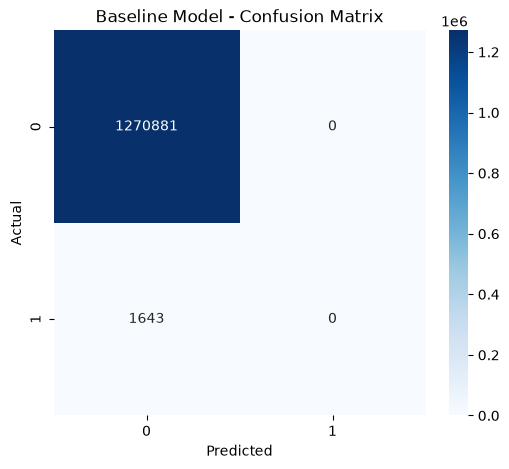

In [53]:
#Display confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, dummy_predictions),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Baseline Model - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [54]:
#class weighting

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

print("Legitimate Class Weight:", weights[0])
print("Fraud Class Weight:", weights[1])

Legitimate Class Weight: 0.5006462050159672
Fraud Class Weight: 387.37412480974126


In [55]:
#Machine learning model

from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_encoded, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [56]:
#Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Make predictions
lr_predictions = lr_model.predict(X_test_encoded)

# Get fraud probabilities
lr_probabilities = lr_model.predict_proba(X_test_encoded)[:, 1]

# Calculate performance metrics
print("LOGISTIC REGRESSION - MODEL PERFORMANCE")
print("----------------------------------------")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions, zero_division=0))
print("Recall:", recall_score(y_test, lr_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, lr_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, lr_probabilities))
print("PR-AUC:", average_precision_score(y_test, lr_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))

LOGISTIC REGRESSION - MODEL PERFORMANCE
----------------------------------------
Accuracy: 0.7325747883733431
Precision: 0.004309057803434366
Recall: 0.8959220937309799
F1 Score: 0.008576864025823819
ROC-AUC: 0.904691215821284
PR-AUC: 0.01616573261905213

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.73      0.85   1270881
           1       0.00      0.90      0.01      1643

    accuracy                           0.73   1272524
   macro avg       0.50      0.81      0.43   1272524
weighted avg       1.00      0.73      0.84   1272524



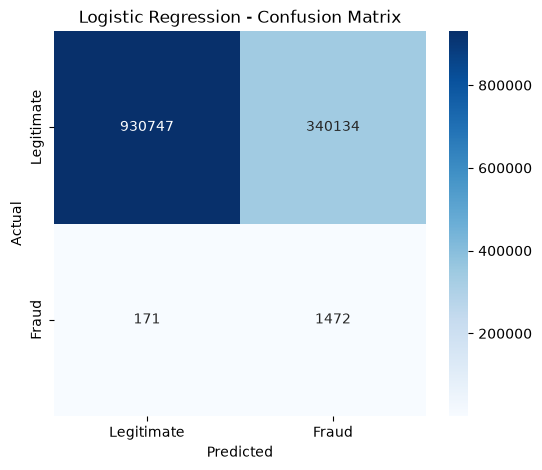

In [57]:
#Confusion Matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [58]:
#better classification threshold

import numpy as np
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, lr_probabilities
)

# Check the best precision we can get while maintaining target recall
target_recalls = [0.90, 0.80, 0.70, 0.60]

print("THRESHOLD ANALYSIS")
print("-" * 65)

for target in target_recalls:

    valid_indices = np.where(recall_values[:-1] >= target)[0]

    if len(valid_indices) > 0:
        best_index = valid_indices[
            np.argmax(precision_values[valid_indices])
        ]

        print(f"\nTarget Recall: {target:.0%}")
        print("Threshold:", thresholds[best_index])
        print("Precision:", precision_values[best_index])
        print("Actual Recall:", recall_values[best_index])

THRESHOLD ANALYSIS
-----------------------------------------------------------------

Target Recall: 90%
Threshold: 0.49931536083143474
Precision: 0.004227840285400659
Actual Recall: 0.9001825928180158

Target Recall: 80%
Threshold: 0.5250655228474748
Precision: 0.007224758671083934
Actual Recall: 0.8003651856360317

Target Recall: 70%
Threshold: 0.5905756926232361
Precision: 0.01088274164881739
Actual Recall: 0.7267194157029824

Target Recall: 60%
Threshold: 0.5905756926232361
Precision: 0.01088274164881739
Actual Recall: 0.7267194157029824


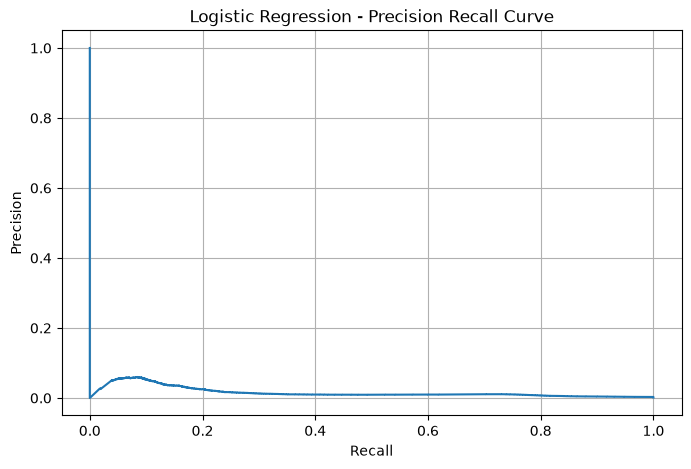

In [59]:
#Visualise the precision-recall trade-off

plt.figure(figsize=(8, 5))

plt.plot(recall_values, precision_values)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision Recall Curve")
plt.grid(True)

plt.show()

In [60]:
#Prepare the training sample

from sklearn.utils import resample
from scipy.sparse import vstack
import numpy as np
import pandas as pd

# Convert target labels into NumPy arrays
y_train_array = y_train.to_numpy()

# Create Boolean masks
legit_mask = y_train_array == 0
fraud_mask = y_train_array == 1

# Separate legitimate and fraudulent transactions
X_train_legit = X_train_encoded[legit_mask]
X_train_fraud = X_train_encoded[fraud_mask]

y_train_legit = y_train_array[legit_mask]
y_train_fraud = y_train_array[fraud_mask]

# Randomly select 500,000 legitimate transactions
X_legit_sample, y_legit_sample = resample(
    X_train_legit,
    y_train_legit,
    replace=False,
    n_samples=500000,
    random_state=42
)

# Combine legitimate sample with all fraud transactions
X_train_sample = vstack([
    X_legit_sample,
    X_train_fraud
])

y_train_sample = np.concatenate([
    y_legit_sample,
    y_train_fraud
])

print("Sampled training shape:", X_train_sample.shape)

print("\nClass distribution:")
print(pd.Series(y_train_sample).value_counts())


Sampled training shape: (506570, 9)

Class distribution:
0    500000
1      6570
Name: count, dtype: int64


In [61]:
#Train Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_sample, y_train_sample)

print("Random Forest training completed!")

Random Forest training completed!


In [62]:
#Evaluate Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predictions
rf_predictions = rf_model.predict(X_test_encoded)

# Fraud probabilities
rf_probabilities = rf_model.predict_proba(X_test_encoded)[:, 1]

# Performance metrics
print("RANDOM FOREST - MODEL PERFORMANCE")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))
print("PR-AUC:", average_precision_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

RANDOM FOREST - MODEL PERFORMANCE
----------------------------------
Accuracy: 0.8847589515011112
Precision: 0.008180930156835079
Recall: 0.7340231284236154
F1 Score: 0.01618151201873084
ROC-AUC: 0.9060561207739508
PR-AUC: 0.18360955368304746

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94   1270881
           1       0.01      0.73      0.02      1643

    accuracy                           0.88   1272524
   macro avg       0.50      0.81      0.48   1272524
weighted avg       1.00      0.88      0.94   1272524



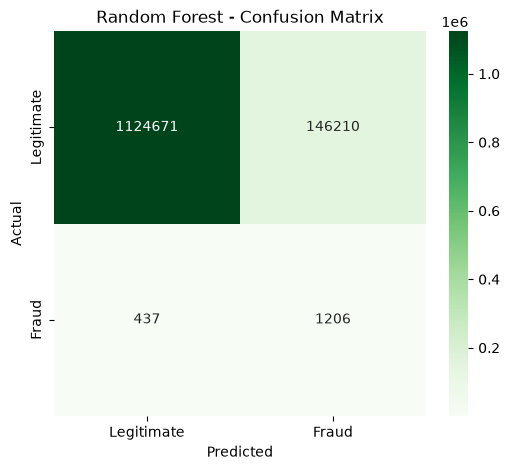

In [63]:
#Confusion Matrix

cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [64]:
#Compare our first two models

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    'Precision': [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ],
    'PR-AUC': [
        average_precision_score(y_test, lr_probabilities),
        average_precision_score(y_test, rf_probabilities)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.732575,0.004309,0.895922,0.008577,0.904691,0.016166
1,Random Forest,0.884759,0.008181,0.734023,0.016182,0.906056,0.183610


In [65]:
#Feature importance analysis

# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                           Feature  Importance
7                      num__amount    0.232563
4               cat__type_TRANSFER    0.209805
8                  num__log_amount    0.187086
0                cat__type_CASH_IN    0.100144
1               cat__type_CASH_OUT    0.080252
3                cat__type_PAYMENT    0.067718
5  cat__destination_account_type_C    0.063639
6  cat__destination_account_type_M    0.056157
2                  cat__type_DEBIT    0.002636


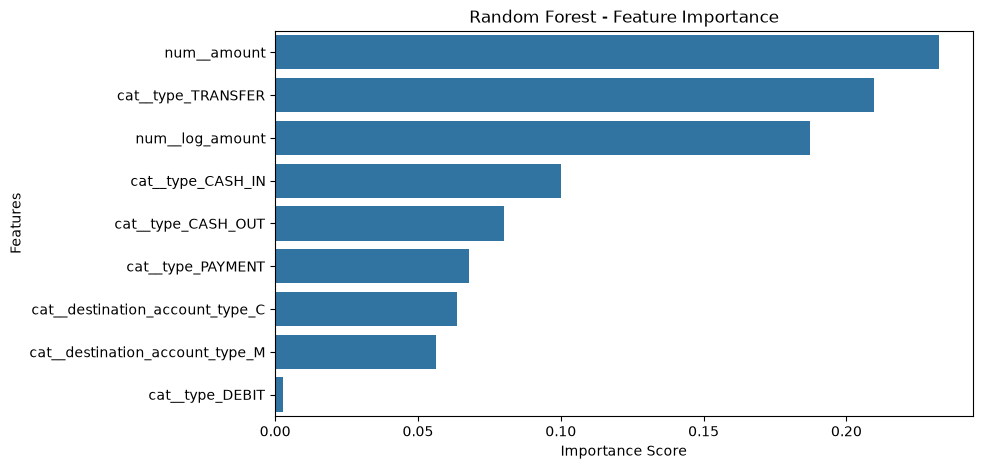

In [66]:
#Visualise feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [67]:
#Train XGBoost

%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [68]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [69]:
#Calculate the class imbalance weight

# Count legitimate and fraudulent transactions
legitimate_count = (y_train == 0).sum()
fraud_count = (y_train == 1).sum()

# Calculate scale_pos_weight
scale_pos_weight = legitimate_count / fraud_count

print("Legitimate Transactions:", legitimate_count)
print("Fraudulent Transactions:", fraud_count)
print("Scale Pos Weight:", scale_pos_weight)

Legitimate Transactions: 5083526
Fraudulent Transactions: 6570
Scale Pos Weight: 773.7482496194825


In [70]:
#Train XGBoost Classifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective='binary:logistic',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Train on the original training dataset
xgb_model.fit(X_train_encoded, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [71]:
#Evaluate XGBoost

#Calculate performance metrics

# Generate predictions
xgb_predictions = xgb_model.predict(X_test_encoded)

# Get fraud probabilities
xgb_probabilities = xgb_model.predict_proba(X_test_encoded)[:, 1]

# Evaluate model
print("XGBOOST - MODEL PERFORMANCE")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, xgb_predictions))
print("Precision:", precision_score(y_test, xgb_predictions, zero_division=0))
print("Recall:", recall_score(y_test, xgb_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, xgb_probabilities))
print("PR-AUC:", average_precision_score(y_test, xgb_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions, zero_division=0))

XGBOOST - MODEL PERFORMANCE
--------------------------------
Accuracy: 0.853039313993292
Precision: 0.0070576847390199015
Recall: 0.8076688983566647
F1 Score: 0.013993093085176496
ROC-AUC: 0.9176774809125311
PR-AUC: 0.18944757349186808

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92   1270881
           1       0.01      0.81      0.01      1643

    accuracy                           0.85   1272524
   macro avg       0.50      0.83      0.47   1272524
weighted avg       1.00      0.85      0.92   1272524



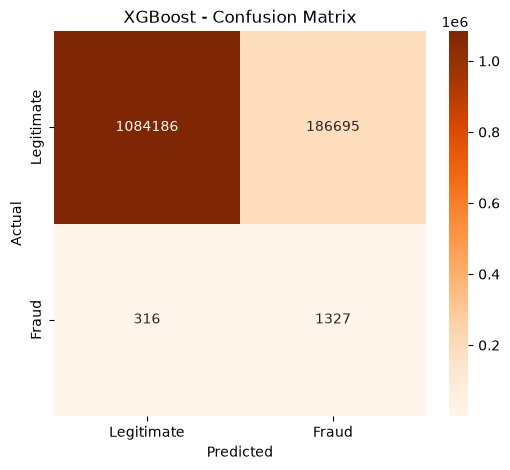

In [72]:
#Confusion matrix

cm_xgb = confusion_matrix(y_test, xgb_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('XGBoost - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [73]:
#Compare all three models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    'Precision': [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0),
        precision_score(y_test, xgb_predictions, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0),
        recall_score(y_test, xgb_predictions, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0),
        f1_score(y_test, xgb_predictions, zero_division=0)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ],
    'PR-AUC': [
        average_precision_score(y_test, lr_probabilities),
        average_precision_score(y_test, rf_probabilities),
        average_precision_score(y_test, xgb_probabilities)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.732575,0.004309,0.895922,0.008577,0.904691,0.016166
1,Random Forest,0.884759,0.008181,0.734023,0.016182,0.906056,0.183610
2,XGBoost,0.853039,0.007058,0.807669,0.013993,0.917677,0.189448


In [74]:
#Create a validation dataset

from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_encoded,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_subtrain.shape)
print("Validation set:", X_val.shape)

print("\nTraining fraud cases:", (y_subtrain == 1).sum())
print("Validation fraud cases:", (y_val == 1).sum())

Training subset: (4072076, 9)
Validation set: (1018020, 9)

Training fraud cases: 5256
Validation fraud cases: 1314


In [75]:
#Train XGBoost on the training subset

# Calculate class weight using the new training subset
subtrain_legit = (y_subtrain == 0).sum()
subtrain_fraud = (y_subtrain == 1).sum()

subtrain_weight = subtrain_legit / subtrain_fraud

print("Training class weight:", subtrain_weight)

# Initialize XGBoost
xgb_validation_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=subtrain_weight,
    objective='binary:logistic',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Train
xgb_validation_model.fit(X_subtrain, y_subtrain)

print("Validation XGBoost training completed!")

Training class weight: 773.748097412481
Validation XGBoost training completed!


In [76]:
#Generate validation predictions

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

# Generate fraud probabilities on validation data
val_probabilities = xgb_validation_model.predict_proba(X_val)[:, 1]

# Calculate Precision-Recall curve
val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

print("VALIDATION PERFORMANCE")
print("-----------------------")
print("ROC-AUC:", roc_auc_score(y_val, val_probabilities))
print("PR-AUC:", average_precision_score(y_val, val_probabilities))

VALIDATION PERFORMANCE
-----------------------
ROC-AUC: 0.910850199205258
PR-AUC: 0.19084784797668727


In [77]:
#Find suitable thresholds

target_recalls = [0.90, 0.80, 0.70, 0.60, 0.50]

print("VALIDATION THRESHOLD ANALYSIS")
print("-" * 65)

for target in target_recalls:

    valid_indices = np.where(val_recall[:-1] >= target)[0]

    if len(valid_indices) > 0:

        best_index = valid_indices[
            np.argmax(val_precision[valid_indices])
        ]

        print(f"\nTarget Recall: {target:.0%}")
        print("Threshold:", val_thresholds[best_index])
        print("Precision:", val_precision[best_index])
        print("Actual Recall:", val_recall[best_index])

VALIDATION THRESHOLD ANALYSIS
-----------------------------------------------------------------

Target Recall: 90%
Threshold: 0.37392893
Precision: 0.0038725208017164688
Actual Recall: 0.9010654490106544

Target Recall: 80%
Threshold: 0.46784455
Precision: 0.006044483259884052
Actual Recall: 0.8006088280060882

Target Recall: 70%
Threshold: 0.71438694
Precision: 0.009902372488159039
Actual Recall: 0.7016742770167428

Target Recall: 60%
Threshold: 0.77181786
Precision: 0.011971873674001333
Actual Recall: 0.6012176560121766

Target Recall: 50%
Threshold: 0.8208525
Precision: 0.015654483192396394
Actual Recall: 0.5114155251141552


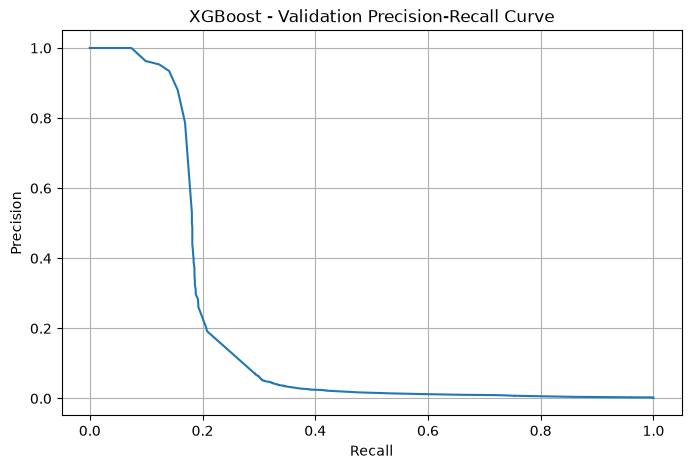

In [78]:
#Visualise the validation precision-recall curve

plt.figure(figsize=(8, 5))

plt.plot(val_recall, val_precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost - Validation Precision-Recall Curve")
plt.grid(True)

plt.show()

In [79]:
#Evaluate the selected threshold on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Selected threshold from validation data
best_threshold = 0.71438694

# Predict probabilities on untouched test data
final_test_probabilities = xgb_validation_model.predict_proba(
    X_test_encoded
)[:, 1]

# Convert probabilities into binary predictions
final_test_predictions = (
    final_test_probabilities >= best_threshold
).astype(int)

# Evaluate
print("XGBOOST - OPTIMISED THRESHOLD PERFORMANCE")
print("------------------------------------------")

print("Selected Threshold:", best_threshold)

print("Accuracy:", accuracy_score(y_test, final_test_predictions))

print("Precision:", precision_score(
    y_test, final_test_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, final_test_predictions, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, final_test_predictions, zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, final_test_predictions, zero_division=0
))

XGBOOST - OPTIMISED THRESHOLD PERFORMANCE
------------------------------------------
Selected Threshold: 0.71438694
Accuracy: 0.9091624205123047
Precision: 0.010263198610943974
Recall: 0.7267194157029824
F1 Score: 0.02024054720675363

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95   1270881
           1       0.01      0.73      0.02      1643

    accuracy                           0.91   1272524
   macro avg       0.50      0.82      0.49   1272524
weighted avg       1.00      0.91      0.95   1272524



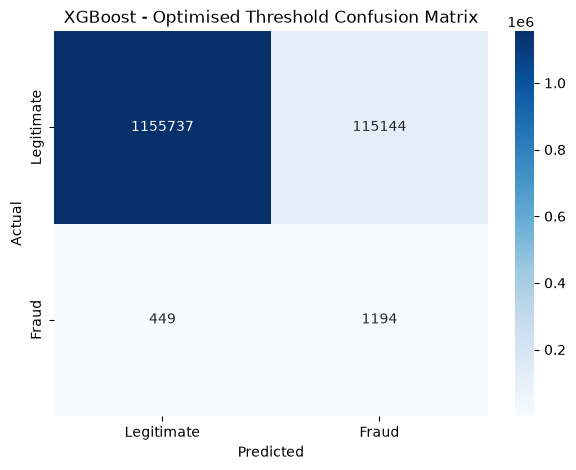

In [80]:
#Plot the final confusion matrix

cm_final = confusion_matrix(y_test, final_test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.title('XGBoost - Optimised Threshold Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [81]:
#Calculate ROC-AUC and PR-AUC

print("ROC-AUC:", roc_auc_score(
    y_test, final_test_probabilities
))

print("PR-AUC:", average_precision_score(
    y_test, final_test_probabilities
))

ROC-AUC: 0.9169268849577932
PR-AUC: 0.1882073494117926


In [82]:
#Feature Validation.

#Remove log_amount

# Identify features except log_amount
selected_features = np.where(
    feature_names != 'num__log_amount'
)[0]

# Create datasets with 8 features
X_subtrain_reduced = X_subtrain[:, selected_features]
X_val_reduced = X_val[:, selected_features]

print("Original number of features:", X_subtrain.shape[1])
print("Reduced number of features:", X_subtrain_reduced.shape[1])

print("\nSelected features:")
print(feature_names[selected_features])

Original number of features: 9
Reduced number of features: 8

Selected features:
['cat__type_CASH_IN' 'cat__type_CASH_OUT' 'cat__type_DEBIT'
 'cat__type_PAYMENT' 'cat__type_TRANSFER'
 'cat__destination_account_type_C' 'cat__destination_account_type_M'
 'num__amount']


In [83]:
#Train XGBoost without log_amount

xgb_reduced_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=subtrain_weight,
    objective='binary:logistic',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

xgb_reduced_model.fit(
    X_subtrain_reduced,
    y_subtrain
)

print("Reduced-feature XGBoost training completed!")

Reduced-feature XGBoost training completed!


In [84]:
#Compare validation performance

# Original model probabilities
original_val_prob = xgb_validation_model.predict_proba(
    X_val
)[:, 1]

# Reduced model probabilities
reduced_val_prob = xgb_reduced_model.predict_proba(
    X_val_reduced
)[:, 1]

# Compare performance
feature_comparison = pd.DataFrame({
    'Model': [
        'XGBoost - 9 Features',
        'XGBoost - 8 Features'
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, original_val_prob),
        roc_auc_score(y_val, reduced_val_prob)
    ],
    'PR-AUC': [
        average_precision_score(y_val, original_val_prob),
        average_precision_score(y_val, reduced_val_prob)
    ]
})

feature_comparison

,Model,ROC-AUC,PR-AUC
0,XGBoost - 9 Features,0.910850,0.190848
1,XGBoost - 8 Features,0.911146,0.191237


In [85]:
#Feature importance of the reduced XGBoost model

# Extract feature importance
reduced_importance = pd.DataFrame({
    'Feature': feature_names[selected_features],
    'Importance': xgb_reduced_model.feature_importances_
})

# Sort by importance
reduced_importance = reduced_importance.sort_values(
    by='Importance',
    ascending=False
)

print(reduced_importance)

                           Feature  Importance
3                cat__type_PAYMENT    0.444014
0                cat__type_CASH_IN    0.321408
5  cat__destination_account_type_C    0.066556
4               cat__type_TRANSFER    0.064937
1               cat__type_CASH_OUT    0.055224
7                      num__amount    0.022434
2                  cat__type_DEBIT    0.016946
6  cat__destination_account_type_M    0.008482


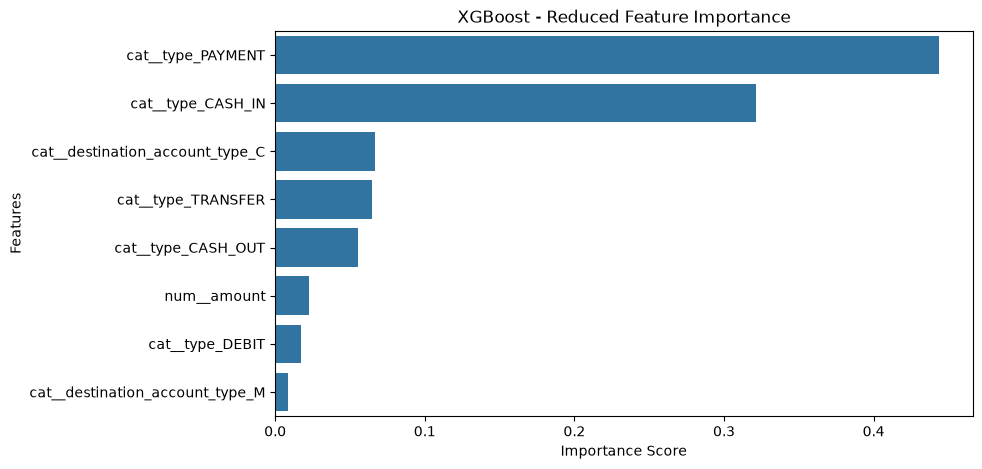

In [86]:
#Visualisation

plt.figure(figsize=(9, 5))

sns.barplot(
    data=reduced_importance,
    x='Importance',
    y='Feature'
)

plt.title('XGBoost - Reduced Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [87]:
#Install SHAP

%pip install shap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [89]:
import shap

print("SHAP imported successfully!")

SHAP imported successfully!


In [90]:
#Prepare a sample for SHAP

# Select a sample of validation transactions
X_shap = X_val_reduced[:1000]

# Get corresponding feature names
reduced_feature_names = feature_names[selected_features]

print("SHAP sample shape:", X_shap.shape)
print("Number of features:", len(reduced_feature_names))

SHAP sample shape: (1000, 8)
Number of features: 8


In [91]:
#Calculate SHAP values

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(xgb_reduced_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values calculated successfully!
SHAP values shape: (1000, 8)


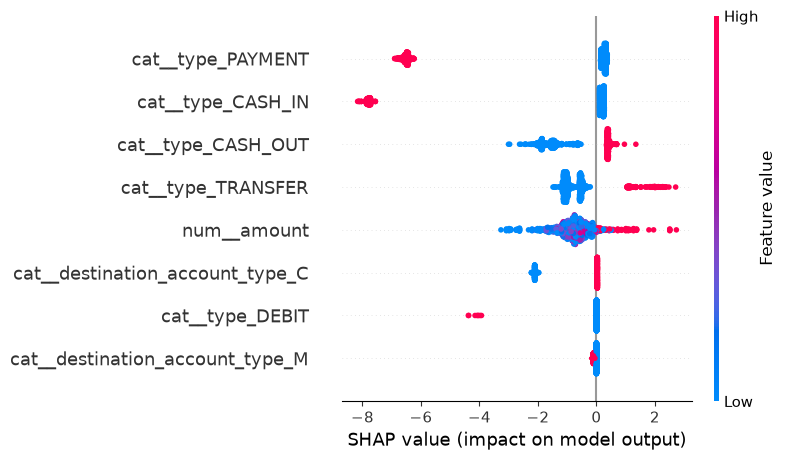

In [92]:
#Generate SHAP summary plot

# Convert sparse sample into a DataFrame for visualisation
X_shap_df = pd.DataFrame(
    X_shap.toarray(),
    columns=reduced_feature_names
)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap_df,
    show=True
)

In [93]:
#Find a fraudulent transaction

# Actual labels for our 1,000 SHAP samples
sample_actual = y_val.iloc[:1000].to_numpy()

# Fraud probabilities from reduced XGBoost
sample_probabilities = xgb_reduced_model.predict_proba(
    X_shap
)[:, 1]

# Find actual fraudulent transactions
fraud_indices = np.where(sample_actual == 1)[0]

print("Fraudulent transactions in sample:", len(fraud_indices))

# Select the actual fraud transaction with the highest predicted probability
fraud_index = fraud_indices[
    np.argmax(sample_probabilities[fraud_indices])
]

print("\nSelected transaction index:", fraud_index)
print("Actual class:", sample_actual[fraud_index])
print("Predicted fraud probability:", sample_probabilities[fraud_index])

Fraudulent transactions in sample: 1

Selected transaction index: 408
Actual class: 1
Predicted fraud probability: 0.31137824


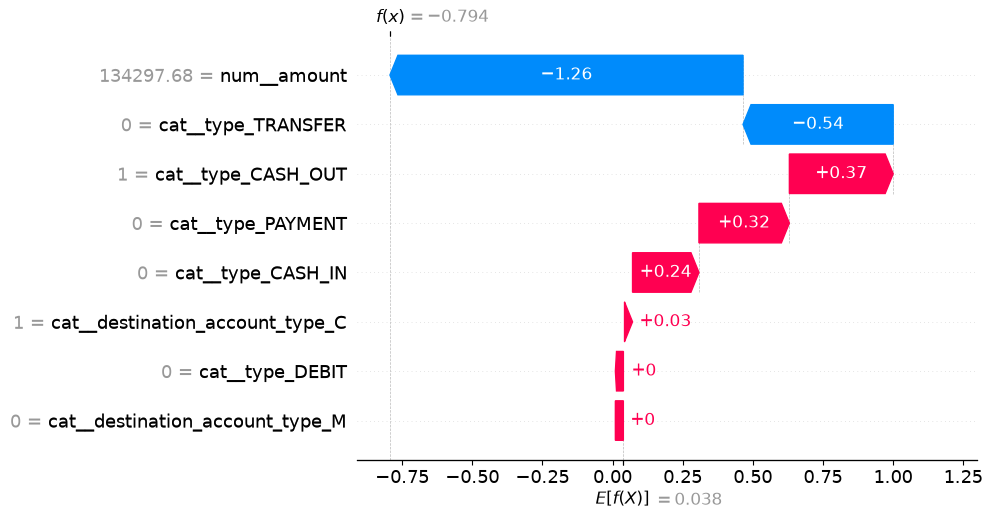

In [94]:
#Generate SHAP waterfall plot

# Create SHAP explanation for the selected transaction
individual_explanation = shap.Explanation(
    values=shap_values[fraud_index],
    base_values=explainer.expected_value,
    data=X_shap_df.iloc[fraud_index].values,
    feature_names=reduced_feature_names
)

# Visualise individual prediction
shap.plots.waterfall(individual_explanation)

In [95]:
#Check false negatives

# Identify false negatives
false_negative_indices = np.where(
    (y_test.to_numpy() == 1) &
    (final_test_predictions == 0)
)[0]

print("Total missed fraud transactions:", len(false_negative_indices))

# Extract missed fraud probabilities
missed_fraud_probabilities = final_test_probabilities[
    false_negative_indices
]

print("\nMissed fraud probability statistics:")
print(pd.Series(missed_fraud_probabilities).describe())

Total missed fraud transactions: 449

Missed fraud probability statistics:
count    449.000000
mean       0.438507
std        0.130189
min        0.046463
25%        0.350219
50%        0.421938
75%        0.513026
max        0.705249
dtype: float64


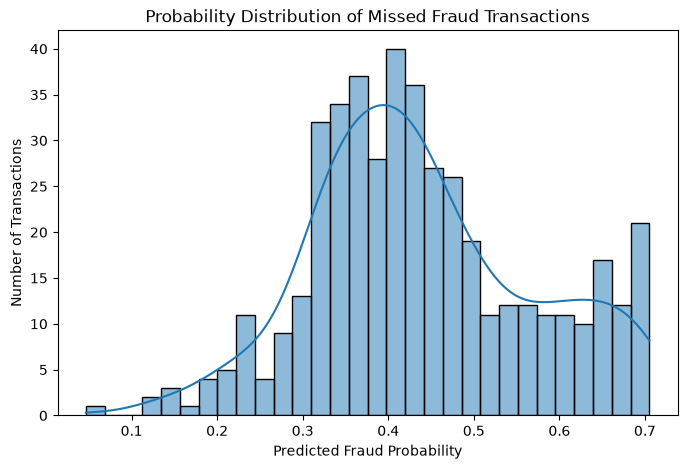

In [96]:
#Examine missed fraud probability distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    missed_fraud_probabilities,
    bins=30,
    kde=True
)

plt.title("Probability Distribution of Missed Fraud Transactions")
plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Number of Transactions")

plt.show()

In [97]:
## Examine transaction time distribution by class
time_analysis = df.groupby('isFraud')['step'].describe()

print(time_analysis)

# Fraud rate by transaction hour (simulation step)
hourly_fraud = df.groupby('step').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum')
)

hourly_fraud['fraud_rate'] = (
    hourly_fraud['fraud_transactions'] /
    hourly_fraud['total_transactions']
)

print("\nHighest fraud-rate steps:")
print(hourly_fraud.sort_values(
    'fraud_rate', ascending=False
).head(15))

             count        mean         std  min    25%    50%    75%    max
isFraud                                                                    
0        6354407.0  243.235663  142.140194  1.0  156.0  239.0  334.0  718.0
1           8213.0  368.413856  216.388690  1.0  181.0  367.0  558.0  743.0

Highest fraud-rate steps:
      total_transactions  fraud_transactions  fraud_rate
step                                                    
727                   12                  12         1.0
743                    8                   8         1.0
742                   14                  14         1.0
410                   20                  20         1.0
411                   16                  16         1.0
412                    8                   8         1.0
414                   16                  16         1.0
415                   16                  16         1.0
417                    6                   6         1.0
418                    6                  

Final Model Performance Comparison

In [98]:
final_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost (Default)',
        'XGBoost (Optimised)'
    ],
    'Accuracy': [
        0.732575,
        0.884759,
        0.853039,
        0.909162
    ],
    'Precision': [
        0.004309,
        0.008181,
        0.007058,
        0.010263
    ],
    'Recall': [
        0.895922,
        0.734023,
        0.807669,
        0.726719
    ],
    'F1 Score': [
        0.008577,
        0.016182,
        0.013993,
        0.020241
    ],
    'ROC-AUC': [
        0.904691,
        0.906056,
        0.917677,
        0.916927
    ],
    'PR-AUC': [
        0.016166,
        0.183610,
        0.189448,
        0.188207
    ]
})

final_comparison.set_index('Model').style.format('{:.4f}')

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.7326,0.0043,0.8959,0.0086,0.9047,0.0162
Random Forest,0.8848,0.0082,0.7340,0.0162,0.9061,0.1836
XGBoost (Default),0.8530,0.0071,0.8077,0.0140,0.9177,0.1894
XGBoost (Optimised),0.9092,0.0103,0.7267,0.0202,0.9169,0.1882


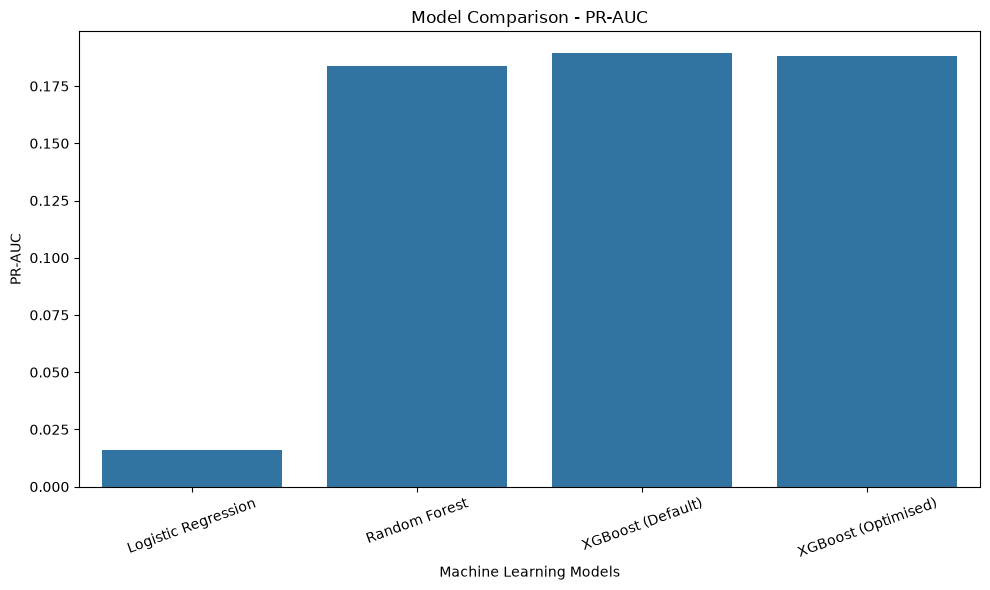

In [99]:
#Visualise model performance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_comparison,
    x='Model',
    y='PR-AUC'
)

plt.title('Model Comparison - PR-AUC')
plt.xlabel('Machine Learning Models')
plt.ylabel('PR-AUC')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Fraud Loss and Investigation Intelligence

## Business Problem

Financial institutions process millions of transactions every day. Their fraud investigation teams have limited time and resources, making it impractical to manually examine every transaction.

The business challenge is not simply to identify fraudulent transactions. It is to understand where suspicious activity is concentrated, which transaction characteristics deserve closer attention, and how investigation resources could be prioritised.

## Business Questions

1. Which transaction types account for the highest concentration of fraudulent activity?
2. What proportion of total transaction value is associated with transactions labelled fraudulent?
3. Are fraudulent transactions concentrated in particular time periods?
4. How do transaction amounts and account balance movements differ between legitimate and fraudulent transactions?
5. What investigation priorities can be developed from these findings?

## Dataset Overview

- Dataset: Synthetic financial transaction dataset
- Total transactions: 6,362,620
- Total features: 11
- Fraudulent transactions: 8,213
- Fraud prevalence: 0.1291%

## Analytical Approach

This supplementary business intelligence analysis uses exploratory data analysis, transaction segmentation, time-period analysis, account balance movement analysis and visualisation to identify patterns associated with fraudulent activity.

The purpose is to translate transaction-level data into business insights that could inform investigation prioritisation.

In [100]:

# FRAUD LOSS & INVESTIGATION INTELLIGENCE

## Display basic information
print("=" * 55)
print("FRAUD BUSINESS INTELLIGENCE ANALYSIS")
print("=" * 55)

print("\nTotal Transactions:", len(df))
print("Total Columns:", len(df.columns))

print("\nAvailable Columns:")
print(df.columns.tolist())

print("\nDataset Preview:")
display(df.head())


FRAUD BUSINESS INTELLIGENCE ANALYSIS

Total Transactions: 6362620
Total Columns: 11

Available Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Dataset Preview:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [101]:

# STEP 2: FRAUD LANDSCAPE ANALYSIS

print("=" * 60)
print("FRAUD LANDSCAPE ANALYSIS")
print("=" * 60)

# 1. Fraud distribution
fraud_counts = df["isFraud"].value_counts()

fraud_percentage = (
    df["isFraud"].value_counts(normalize=True) * 100
)

print("\n1. TRANSACTION DISTRIBUTION")
print("Legitimate transactions:", fraud_counts.get(0, 0))
print("Fraudulent transactions:", fraud_counts.get(1, 0))

print("\n2. FRAUD PERCENTAGE")
print(fraud_percentage.round(4))

# 2. Fraud by transaction type
print("\n3. FRAUD BY TRANSACTION TYPE")

fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"]
)

fraud_by_type.columns = [
    "Legitimate", "Fraudulent"
]

print(fraud_by_type)

# 3. Fraud rate by transaction type
print("\n4. FRAUD RATE BY TRANSACTION TYPE")

fraud_rate = (
    df.groupby("type")["isFraud"].mean() * 100
).sort_values(ascending=False)

print(fraud_rate.round(4))

# 4. Flagged versus unflagged fraud
print("\n5. FRAUD FLAGGING ANALYSIS")

print(pd.crosstab(
    df["isFraud"],
    df["isFlaggedFraud"]
))


FRAUD LANDSCAPE ANALYSIS

1. TRANSACTION DISTRIBUTION
Legitimate transactions: 6354407
Fraudulent transactions: 8213

2. FRAUD PERCENTAGE
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

3. FRAUD BY TRANSACTION TYPE
          Legitimate  Fraudulent
type                            
CASH_IN      1399284           0
CASH_OUT     2233384        4116
DEBIT          41432           0
PAYMENT      2151495           0
TRANSFER      528812        4097

4. FRAUD RATE BY TRANSACTION TYPE
type
TRANSFER    0.7688
CASH_OUT    0.1840
CASH_IN     0.0000
DEBIT       0.0000
PAYMENT     0.0000
Name: isFraud, dtype: float64

5. FRAUD FLAGGING ANALYSIS
isFlaggedFraud        0   1
isFraud                    
0               6354407   0
1                  8197  16


Business implication: A bank cannot rely on overall accuracy alone. A system that labels every transaction legitimate would achieve approximately 99.87% accuracy while detecting zero fraud.

In [102]:
# STEP 3: FRAUD-ASSOCIATED TRANSACTION VALUE

print("=" * 60)
print("FRAUD-ASSOCIATED TRANSACTION VALUE")
print("=" * 60)

# Separate legitimate and fraudulent transactions
fraud_transactions = df[df["isFraud"] == 1]
legitimate_transactions = df[df["isFraud"] == 0]

# Calculate transaction values
fraud_value = fraud_transactions["amount"].sum()
legitimate_value = legitimate_transactions["amount"].sum()
total_value = df["amount"].sum()

print("\n1. TOTAL TRANSACTION VALUE")
print(f"All transactions: {total_value:,.2f}")
print(f"Legitimate transactions: {legitimate_value:,.2f}")
print(f"Fraud-associated transactions: {fraud_value:,.2f}")

print("\n2. FRAUD-ASSOCIATED VALUE AS A PERCENTAGE")
print(f"{(fraud_value / total_value) * 100:.4f}%")

print("\n3. FRAUD-ASSOCIATED VALUE BY TRANSACTION TYPE")

fraud_value_by_type = (
    fraud_transactions.groupby("type")["amount"]
    .agg(["count", "sum", "mean", "median"])
    .sort_values("sum", ascending=False)
)

print(fraud_value_by_type.round(2))

FRAUD-ASSOCIATED TRANSACTION VALUE

1. TOTAL TRANSACTION VALUE
All transactions: 1,144,392,944,759.77
Legitimate transactions: 1,132,336,529,331.93
Fraud-associated transactions: 12,056,415,427.84

2. FRAUD-ASSOCIATED VALUE AS A PERCENTAGE
1.0535%

3. FRAUD-ASSOCIATED VALUE BY TRANSACTION TYPE
          count           sum        mean     median
type                                                
TRANSFER   4097  6.067213e+09  1480891.67  445705.76
CASH_OUT   4116  5.989202e+09  1455102.59  435516.90


Business implication: Investigation priority should consider more than the number of suspicious transactions. The potential transaction value also matters.

In [103]:
# STEP 4: TRANSACTION TYPE RISK COMPARISON

type_analysis = df.groupby("type").agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum"),
    total_transaction_value=("amount", "sum")
)

type_analysis["fraud_rate_pct"] = (
    type_analysis["fraudulent_transactions"]
    / type_analysis["total_transactions"] * 100
)

fraud_value_by_type = (
    df[df["isFraud"] == 1]
    .groupby("type")["amount"]
    .sum()
)

type_analysis["fraud_associated_value"] = (
    fraud_value_by_type
)

type_analysis["share_of_fraud_value_pct"] = (
    type_analysis["fraud_associated_value"]
    / fraud_value * 100
)

type_analysis = type_analysis.fillna(0).sort_values(
    "fraud_associated_value", ascending=False
)

print("TRANSACTION TYPE RISK COMPARISON")
print("=" * 75)

print(type_analysis.round(2))

TRANSACTION TYPE RISK COMPARISON
          total_transactions  fraudulent_transactions  \
type                                                    
TRANSFER              532909                     4097   
CASH_OUT             2237500                     4116   
CASH_IN              1399284                        0   
DEBIT                  41432                        0   
PAYMENT              2151495                        0   

          total_transaction_value  fraud_rate_pct  fraud_associated_value  \
type                                                                        
TRANSFER             4.852920e+11            0.77            6.067213e+09   
CASH_OUT             3.944130e+11            0.18            5.989202e+09   
CASH_IN              2.363674e+11            0.00            0.000000e+00   
DEBIT                2.271992e+08            0.00            0.000000e+00   
PAYMENT              2.809337e+10            0.00            0.000000e+00   

          share_of_fraud_va

- TRANSFER has a fraud rate of approximately 0.77%, compared with 0.18% for CASH_OUT.
- CASH_OUT processes more than four times as many transactions as TRANSFER.
- Despite this difference in volume, both contribute almost equal fraud-associated transaction value.
Business interpretation: TRANSFER has a higher observed fraud rate, while CASH_OUT has a much larger transaction volume. An investigation strategy should consider both risk concentration and workload.

One caution: zero labelled fraud in CASH_IN, DEBIT and PAYMENT is a finding about this dataset, not proof that these transaction types are inherently fraud-free.

In [104]:
# STEP 5: FRAUD TREND OVER TIME

print("=" * 60)
print("FRAUD TREND OVER TIME")
print("=" * 60)

# Group transactions by time step
fraud_by_step = df.groupby("step").agg(
    total_transactions=("isFraud", "count"),
    fraudulent_transactions=("isFraud", "sum"),
    total_transaction_value=("amount", "sum")
)

# Calculate fraud rate
fraud_by_step["fraud_rate_pct"] = (
    fraud_by_step["fraudulent_transactions"]
    / fraud_by_step["total_transactions"] * 100
)

# Calculate fraud-associated transaction value
fraud_value_by_step = (
    df[df["isFraud"] == 1]
    .groupby("step")["amount"]
    .sum()
)

fraud_by_step["fraud_associated_value"] = (
    fraud_value_by_step
)

fraud_by_step = fraud_by_step.fillna(0)

print("\n1. TIME PERIOD SUMMARY")
print("Total time steps:", df["step"].nunique())
print("First step:", df["step"].min())
print("Last step:", df["step"].max())

print("\n2. TOP 10 TIME STEPS BY FRAUD COUNT")
print(
    fraud_by_step.sort_values(
        "fraudulent_transactions", ascending=False
    ).head(10).round(2)
)

print("\n3. TOP 10 TIME STEPS BY FRAUD-ASSOCIATED VALUE")
print(
    fraud_by_step.sort_values(
        "fraud_associated_value", ascending=False
    ).head(10).round(2)
)

FRAUD TREND OVER TIME

1. TIME PERIOD SUMMARY
Total time steps: 743
First step: 1
Last step: 743

2. TOP 10 TIME STEPS BY FRAUD COUNT
      total_transactions  fraudulent_transactions  total_transaction_value  \
step                                                                         
212                34047                       40             4.386135e+09   
523                   30                       30             6.954014e+07   
249                23209                       28             3.792801e+09   
425                   28                       28             1.102985e+08   
501                   28                       28             7.961467e+07   
387                   28                       28             1.472376e+08   
730                   28                       28             1.150034e+08   
398                26656                       26             5.024591e+09   
160                27765                       26             4.657391e+09   
694     

Business insight: Fraud rate must be interpreted alongside transaction volume. Otherwise, small groups can appear more dangerous than large groups.

In [105]:
# STEP 6: INVESTIGATE UNUSUAL FRAUD TIME STEPS

print("=" * 65)
print("INVESTIGATION OF UNUSUAL FRAUD TIME STEPS")
print("=" * 65)

# Time steps with 100% fraud rate
high_fraud_steps = fraud_by_step[
    fraud_by_step["fraud_rate_pct"] == 100
].sort_values(
    "fraudulent_transactions", ascending=False
)

print("\n1. NUMBER OF TIME STEPS WITH 100% FRAUD RATE")
print(len(high_fraud_steps))

print("\n2. TRANSACTION VOLUME AT THESE TIME STEPS")
print(
    high_fraud_steps[
        ["total_transactions", "fraudulent_transactions",
         "fraud_rate_pct", "fraud_associated_value"]
    ].head(15).round(2)
)

print("\n3. OVERALL TRANSACTION VOLUME STATISTICS")
print(
    fraud_by_step["total_transactions"].describe().round(2)
)

print("\n4. FRAUDULENT TRANSACTIONS BY TIME STEP")
print(
    fraud_by_step["fraudulent_transactions"].describe().round(2)
)

INVESTIGATION OF UNUSUAL FRAUD TIME STEPS

1. NUMBER OF TIME STEPS WITH 100% FRAUD RATE
320

2. TRANSACTION VOLUME AT THESE TIME STEPS
      total_transactions  fraudulent_transactions  fraud_rate_pct  \
step                                                                
523                   30                       30           100.0   
501                   28                       28           100.0   
425                   28                       28           100.0   
730                   28                       28           100.0   
387                   28                       28           100.0   
66                    24                       24           100.0   
625                   24                       24           100.0   
149                   22                       22           100.0   
680                   22                       22           100.0   
726                   22                       22           100.0   
741                   22             

In [106]:
# STEP 7: TIME PERIOD VOLUME CLASSIFICATION

def classify_volume(volume):
    if volume < 529:
        return "Low Volume"
    elif volume < 12317:
        return "Medium Volume"
    else:
        return "High Volume"

fraud_by_step["volume_category"] = (
    fraud_by_step["total_transactions"].apply(classify_volume)
)

volume_analysis = fraud_by_step.groupby("volume_category").agg(
    time_steps=("total_transactions", "count"),
    total_transactions=("total_transactions", "sum"),
    fraudulent_transactions=("fraudulent_transactions", "sum"),
    fraud_associated_value=("fraud_associated_value", "sum")
)

volume_analysis["fraud_rate_pct"] = (
    volume_analysis["fraudulent_transactions"]
    / volume_analysis["total_transactions"] * 100
)

volume_analysis["share_of_fraud_count_pct"] = (
    volume_analysis["fraudulent_transactions"]
    / fraud_by_step["fraudulent_transactions"].sum() * 100
)

print("FRAUD ANALYSIS BY TRANSACTION VOLUME")
print("=" * 70)
print(volume_analysis.round(2))

FRAUD ANALYSIS BY TRANSACTION VOLUME
                 time_steps  total_transactions  fraudulent_transactions  \
volume_category                                                            
High Volume             186             5616438                     2152   
Low Volume              370               14362                     4150   
Medium Volume           187              731820                     1911   

                 fraud_associated_value  fraud_rate_pct  \
volume_category                                           
High Volume                3.099865e+09            0.04   
Low Volume                 6.331454e+09           28.90   
Medium Volume              2.625096e+09            0.26   

                 share_of_fraud_count_pct  
volume_category                            
High Volume                         26.20  
Low Volume                          50.53  
Medium Volume                       23.27  


Business implication: An investigation strategy that only monitors high-volume periods could overlook a substantial amount of suspicious activity.

However, this is a dataset-level association, not evidence that low transaction volume causes fraud. It is also worth investigating whether the simulation generated these low-volume periods in a particular way.

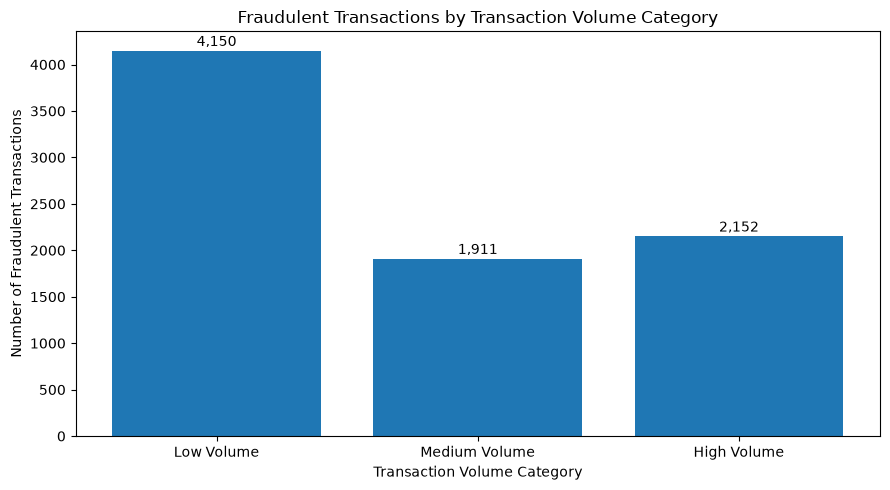

In [107]:
# STEP 8: FRAUD COUNT BY TRANSACTION VOLUME

import matplotlib.pyplot as plt

volume_order = ["Low Volume", "Medium Volume", "High Volume"]

plot_data = volume_analysis.reindex(volume_order)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data.index,
    plot_data["fraudulent_transactions"]
)

plt.title("Fraudulent Transactions by Transaction Volume Category")
plt.xlabel("Transaction Volume Category")
plt.ylabel("Number of Fraudulent Transactions")

for i, value in enumerate(plot_data["fraudulent_transactions"]):
    plt.text(i, value + 50, f"{value:,.0f}", ha="center")

plt.tight_layout()
plt.show()

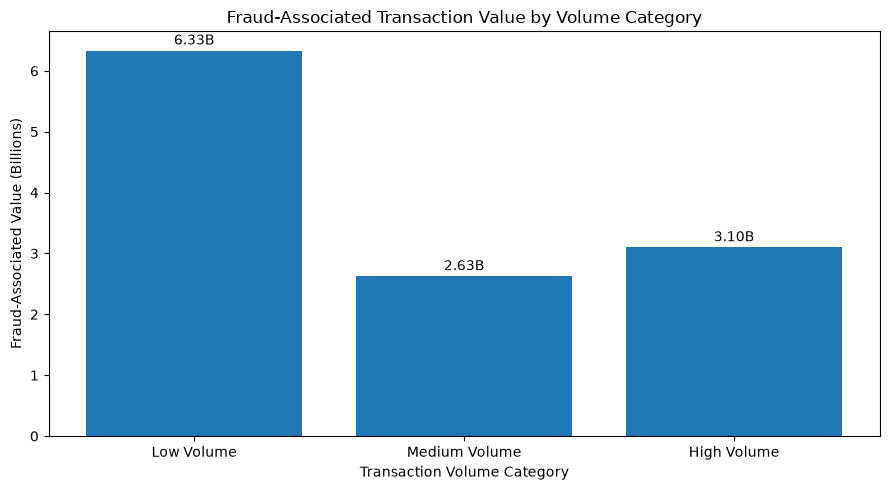

In [108]:
# STEP 9: FRAUD-ASSOCIATED VALUE BY VOLUME CATEGORY

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data.index,
    plot_data["fraud_associated_value"] / 1_000_000_000
)

plt.title("Fraud-Associated Transaction Value by Volume Category")
plt.xlabel("Transaction Volume Category")
plt.ylabel("Fraud-Associated Value (Billions)")

for i, value in enumerate(
    plot_data["fraud_associated_value"] / 1_000_000_000
):
    plt.text(i, value + 0.1, f"{value:.2f}B", ha="center")

plt.tight_layout()
plt.show()

In [109]:
# STEP 10: FRAUDULENT VS LEGITIMATE TRANSACTION PROFILE

print("=" * 70)
print("FRAUDULENT VS LEGITIMATE TRANSACTION PROFILE")
print("=" * 70)

transaction_profile = df.groupby("isFraud").agg(
    transaction_count=("amount", "count"),
    average_amount=("amount", "mean"),
    median_amount=("amount", "median"),
    average_sender_balance_before=("oldbalanceOrg", "mean"),
    average_sender_balance_after=("newbalanceOrig", "mean"),
    average_recipient_balance_before=("oldbalanceDest", "mean"),
    average_recipient_balance_after=("newbalanceDest", "mean")
)

transaction_profile.index = ["Legitimate", "Fraudulent"]

print(transaction_profile.round(2))

FRAUDULENT VS LEGITIMATE TRANSACTION PROFILE
            transaction_count  average_amount  median_amount  \
Legitimate            6354407       178197.04       74684.72   
Fraudulent               8213      1467967.30      441423.44   

            average_sender_balance_before  average_sender_balance_after  \
Legitimate                      832828.71                     855970.23   
Fraudulent                     1649667.61                     192392.63   

            average_recipient_balance_before  average_recipient_balance_after  
Legitimate                        1101420.87                       1224925.68  
Fraudulent                         544249.62                       1279707.62  


Business implication: Transaction amount and account balance movements may help identify suspicious financial activity. However, these are differences in group averages, not proof that any individual transaction is fraudulent.

In [110]:
# STEP 11: ACCOUNT BALANCE MOVEMENT ANALYSIS

df["sender_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["recipient_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

balance_analysis = df.groupby("isFraud").agg(
    average_sender_balance_change=("sender_balance_change", "mean"),
    median_sender_balance_change=("sender_balance_change", "median"),
    average_recipient_balance_change=("recipient_balance_change", "mean"),
    median_recipient_balance_change=("recipient_balance_change", "median")
)

balance_analysis.index = ["Legitimate", "Fraudulent"]

print("=" * 70)
print("ACCOUNT BALANCE MOVEMENT ANALYSIS")
print("=" * 70)

print(balance_analysis.round(2))

ACCOUNT BALANCE MOVEMENT ANALYSIS
            average_sender_balance_change  median_sender_balance_change  \
Legitimate                      -23141.52                          0.00   
Fraudulent                     1457274.97                     436317.49   

            average_recipient_balance_change  median_recipient_balance_change  
Legitimate                         123504.81                              0.0  
Fraudulent                         735458.00                              0.0  


In [111]:
# STEP 12: ZERO BALANCE MOVEMENT ANALYSIS

print("=" * 70)
print("ZERO BALANCE MOVEMENT ANALYSIS")
print("=" * 70)

zero_balance_analysis = df.groupby("isFraud").agg(
    sender_zero_change=("sender_balance_change",
                        lambda x: (x == 0).mean() * 100),

    recipient_zero_change=("recipient_balance_change",
                           lambda x: (x == 0).mean() * 100),

    sender_negative_change=("sender_balance_change",
                            lambda x: (x < 0).mean() * 100),

    recipient_negative_change=("recipient_balance_change",
                               lambda x: (x < 0).mean() * 100)
)

zero_balance_analysis.index = ["Legitimate", "Fraudulent"]

print(zero_balance_analysis.round(2))

ZERO BALANCE MOVEMENT ANALYSIS
            sender_zero_change  recipient_zero_change  sender_negative_change  \
Legitimate               32.87                  36.40                   22.02   
Fraudulent                0.69                  49.75                    0.00   

            recipient_negative_change  
Legitimate                      19.50  
Fraudulent                       0.33  


Business implications
These patterns suggest two potentially useful investigation signals:
- Sender balance reduction: Fraudulent transactions almost always show a reduction in sender balance.
- Recipient balance movement: In many fraudulent transactions, the recipient's recorded balance does not increase.

In [112]:
# STEP 13: FRAUD PROFILE BY TRANSACTION TYPE

fraud_type_profile = df[df["isFraud"] == 1].groupby("type").agg(
    fraud_count=("amount", "count"),
    average_amount=("amount", "mean"),
    median_amount=("amount", "median"),
    average_sender_balance_change=("sender_balance_change", "mean"),
    average_recipient_balance_change=("recipient_balance_change", "mean")
)

fraud_type_profile["share_of_fraud_count_pct"] = (
    fraud_type_profile["fraud_count"]
    / fraud_type_profile["fraud_count"].sum() * 100
)

print("=" * 75)
print("FRAUD PROFILE BY TRANSACTION TYPE")
print("=" * 75)

print(fraud_type_profile.round(2))

FRAUD PROFILE BY TRANSACTION TYPE
          fraud_count  average_amount  median_amount  \
type                                                   
CASH_OUT         4116      1455102.59      435516.90   
TRANSFER         4097      1480891.67      445705.76   

          average_sender_balance_change  average_recipient_balance_change  \
type                                                                        
CASH_OUT                     1453796.46                        1464626.42   
TRANSFER                     1460769.62                           2908.03   

          share_of_fraud_count_pct  
type                                
CASH_OUT                     50.12  
TRANSFER                     49.88  


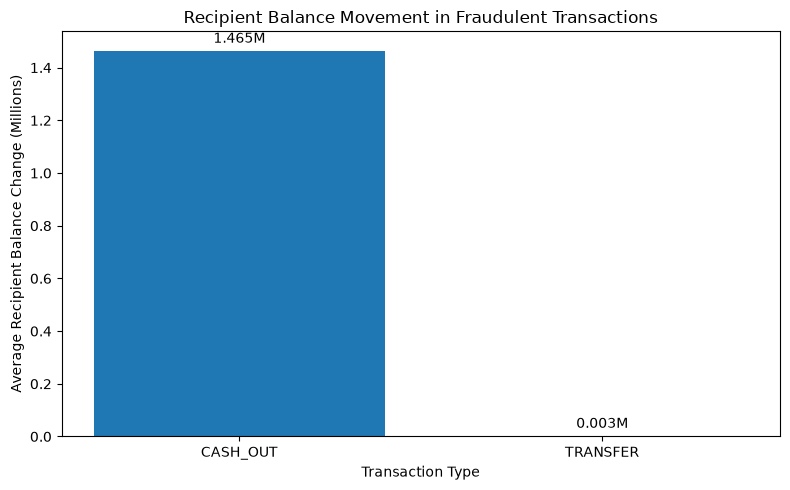

In [113]:
# STEP 14: RECIPIENT BALANCE MOVEMENT BY FRAUD TYPE

plt.figure(figsize=(8, 5))

plt.bar(
    fraud_type_profile.index,
    fraud_type_profile["average_recipient_balance_change"] / 1_000_000
)

plt.title("Recipient Balance Movement in Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Average Recipient Balance Change (Millions)")

for i, value in enumerate(
    fraud_type_profile["average_recipient_balance_change"] / 1_000_000
):
    plt.text(i, value + 0.03, f"{value:.3f}M", ha="center")

plt.tight_layout()
plt.show()

In [114]:
# STEP 15: FRAUD INVESTIGATION PRIORITY FRAMEWORK

investigation_summary = fraud_type_profile.copy()

investigation_summary["fraud_associated_value"] = (
    df[df["isFraud"] == 1]
    .groupby("type")["amount"]
    .sum()
)

investigation_summary["fraud_rate_pct"] = (
    fraud_rate
)

investigation_summary["priority"] = [
    "High Priority" if x > 0 else "No labelled fraud observed"
    for x in investigation_summary["fraud_count"]
]

investigation_summary = investigation_summary[
    [
        "fraud_count",
        "fraud_rate_pct",
        "fraud_associated_value",
        "average_amount",
        "average_sender_balance_change",
        "average_recipient_balance_change",
        "priority"
    ]
]

print("=" * 85)
print("FRAUD INVESTIGATION PRIORITY FRAMEWORK")
print("=" * 85)

print(investigation_summary.round(2))

FRAUD INVESTIGATION PRIORITY FRAMEWORK
          fraud_count  fraud_rate_pct  fraud_associated_value  average_amount  \
type                                                                            
CASH_OUT         4116            0.18            5.989202e+09      1455102.59   
TRANSFER         4097            0.77            6.067213e+09      1480891.67   

          average_sender_balance_change  average_recipient_balance_change  \
type                                                                        
CASH_OUT                     1453796.46                        1464626.42   
TRANSFER                     1460769.62                           2908.03   

               priority  
type                     
CASH_OUT  High Priority  
TRANSFER  High Priority  


# Executive Summary: Fraud Loss and Investigation Intelligence

## Business Problem

Financial institutions process millions of transactions, making it impractical for investigation teams to manually examine every transaction. The challenge is to understand where fraudulent activity is concentrated, identify transaction characteristics associated with fraud, and develop evidence-based priorities for further investigation.

This analysis examines 6.36 million simulated financial transactions to identify patterns in fraudulent transaction frequency, transaction value, transaction type, time periods, and account balance movements.

## Key Findings

### 1. Fraud is rare but financially significant

- Total transactions analysed: 6,362,620
- Fraudulent transactions: 8,213
- Fraud rate: 0.1291%
- Fraud-associated transaction value: 12.06 billion
- Fraud-associated value as a share of total transaction value: 1.0535%

Fraudulent transactions represent a small share of transaction volume but a larger share of total transaction value.

### 2. Fraud is concentrated in two transaction types

TRANSFER and CASH_OUT account for all 8,213 transactions labelled fraudulent.

- TRANSFER: 4,097 fraudulent transactions, with a 0.7688% fraud rate.
- CASH_OUT: 4,116 fraudulent transactions, with a 0.1840% fraud rate.

Both categories contribute approximately half of the total fraud-associated transaction value.

### 3. Existing fraud flagging has limited coverage

Only 16 of the 8,213 fraudulent transactions were flagged by the existing `isFlaggedFraud` indicator. This represents approximately 0.195% of labelled fraudulent transactions.

### 4. Fraud-associated activity is concentrated in low-volume periods

Low-volume time periods account for:
- 50.53% of fraudulent transactions.
- 52.52% of fraud-associated transaction value.

This suggests that monitoring only high-volume periods could overlook substantial suspicious activity.

### 5. Fraudulent transactions have higher transaction amounts

The average fraudulent transaction amount is approximately 1.47 million, compared with 178,197 for legitimate transactions.

The median fraudulent transaction amount is also substantially higher.

### 6. Account balance movements show distinct patterns

Fraudulent transactions have a much higher average sender balance reduction than legitimate transactions.

Recipient balance movements also differ between CASH_OUT and TRANSFER:
- CASH_OUT has an average recipient balance increase of approximately 1.46 million.
- TRANSFER has an average recipient balance increase of approximately 2,908.

These patterns may provide useful signals for further investigation.

## Recommended Investigation Priorities

1. Give particular attention to TRANSFER and CASH_OUT transactions, which account for all labelled fraud in this dataset.
2. Consider both transaction value and fraud frequency when prioritising suspicious activity.
3. Investigate unusual sender balance reductions and recipient balance movements.
4. Avoid relying exclusively on high-volume periods when monitoring transactions.
5. Evaluate existing fraud detection flags and investigate opportunities to improve detection coverage.

## Conclusion

The analysis identifies clear concentrations of fraudulent activity across transaction types, transaction values, time periods, and account balance movements.

The findings provide an initial evidence-based framework for understanding where investigation attention may be most valuable. Further validation and model-based testing would be necessary before implementing these patterns as operational fraud detection rules.

# Limitations and Considerations

## 1. Synthetic Dataset

The analysis uses a simulated financial transaction dataset rather than real banking transaction records. Patterns identified here may not fully represent actual customer behaviour or real-world fraud strategies.

## 2. Fraud-Associated Value Is Not Confirmed Financial Loss

The 12.06 billion figure represents the total value of transactions labelled fraudulent. It does not establish the actual financial loss incurred by a financial institution, the amount recovered, or the final economic impact.

## 3. Severe Class Imbalance

Fraudulent transactions account for only 0.1291% of the dataset. This imbalance means that accuracy alone is not an appropriate measure of fraud detection performance.

## 4. Time-Based Findings Require Further Validation

The low-volume periods show a disproportionately high concentration of fraudulent transactions. However, the dataset contains 743 simulated time steps, and these should not be interpreted as actual dates or business hours. The observed pattern may reflect the dataset's simulation process.

## 5. Aggregate Statistics Can Hide Individual Differences

Average transaction amounts and balance movements do not describe every fraudulent transaction. A small number of unusually large transactions may influence averages. Median values and transaction-level analysis are also important.

## 6. Observed Patterns Do Not Establish Causation

The relationships between transaction type, transaction amount, account balance movements, and fraud labels are descriptive associations. They do not prove that these characteristics cause fraudulent activity.

## 7. Investigation Priorities Are Preliminary

The proposed priorities are based on historical patterns in this dataset. They have not been tested as live investigation rules, and they should not be treated as a validated operational fraud detection system.

## Overall Consideration

The findings should be viewed as an exploratory business intelligence analysis. Real-world implementation would require validation on representative banking data, assessment of false positives and false negatives, operational testing, and ongoing monitoring.